# PCA a Hitters
Maria Fernanda Gómez Flores
## Objetivo general

En esta tarea voy a usar el dataset Hitters de mi primer examen para comparar XGBoost con PCA usando 2 componentes 4 componentes y todas las componentes

también voy a comparar esos resultados con XGBoost usando todas las variables originales para ver cuál funciona mejor para predecir Salary

## 1. Revisión inicial de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

df = pd.read_csv('Hitters_examen (1).csv')
df.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [2]:
df.shape

(322, 20)

In [3]:
df.isna().sum()

AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
Salary       59
NewLeague     0
dtype: int64

In [4]:
df = df.dropna()
df.shape

(263, 20)

In [5]:
df[['Salary']].describe().round(2)

,Salary
count,263.00
mean,535.93
std,451.12
min,67.50
25%,190.00
50%,425.00
75%,750.00
max,2460.00


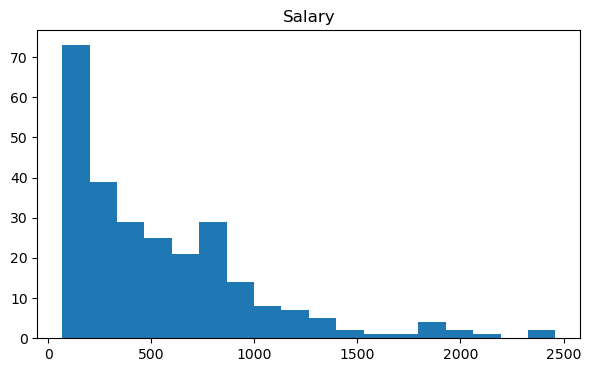

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['Salary'], bins=18)
ax.set_title('Salary')
plt.show()

### Conclusión del análisis exploratorio

Primero revisé Hitters y eliminé las 59 observaciones que no tenían Salary entonces me quedaron 263 jugadores

vi que hay bastante diferencia entre los salarios y que la mayoría gana menos que unos cuantos jugadores con salarios muy altos

## 2. Separación de datos

In [7]:
df_modelos = pd.get_dummies(df)
target = 'Salary'
X = df_modelos.drop(target, axis=1)
y = df_modelos[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_train_modelo, X_valid, y_train_modelo, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

X_train_modelo.shape, X_valid.shape, X_test.shape

((147, 22), (37, 22), (79, 22))

### Conclusión de la separación

Separé los datos igual que en Hitters4 usando 70% para entrenamiento y 30% para prueba

también usé una parte de entrenamiento para validación y así comparar los 4 modelos con los mismos 79 jugadores de prueba

el escalado y PCA los voy a ajustar solo con entrenamiento para no usar información de los datos de prueba

## 3. PCA con 2 componentes

In [8]:
pipeline_pca2 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

pipeline_pca2.fit(X_train_modelo)

X_train_pca2 = pipeline_pca2.transform(X_train_modelo)
X_valid_pca2 = pipeline_pca2.transform(X_valid)
X_test_pca2 = pipeline_pca2.transform(X_test)

X_train_pca2 = pd.DataFrame(X_train_pca2, columns=[f'PC{i+1}' for i in range(X_train_pca2.shape[1])])
X_valid_pca2 = pd.DataFrame(X_valid_pca2, columns=[f'PC{i+1}' for i in range(X_valid_pca2.shape[1])])
X_test_pca2 = pd.DataFrame(X_test_pca2, columns=[f'PC{i+1}' for i in range(X_test_pca2.shape[1])])

pca_objeto2 = pipeline_pca2.named_steps['pca']
pca_objeto2.explained_variance_ratio_

array([0.32117886, 0.20801492])

In [9]:
pca_objeto2.explained_variance_ratio_.sum()

np.float64(0.5291937799313164)

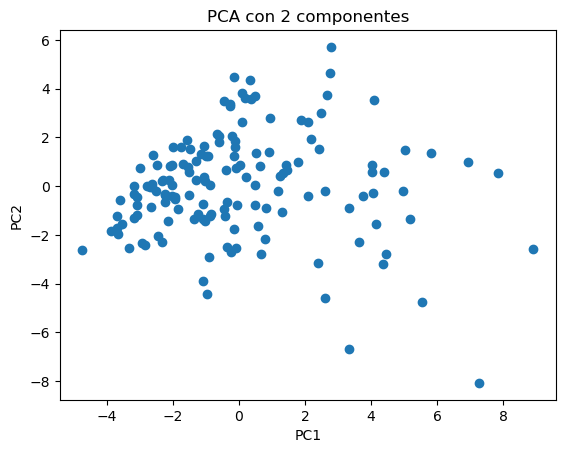

In [10]:
plt.scatter(X_train_pca2.PC1, X_train_pca2.PC2)
plt.title('PCA con 2 componentes')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [11]:
model_pca2 = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_pca2.fit(
    X_train_pca2, y_train_modelo,
    eval_set=[(X_train_pca2, y_train_modelo), (X_valid_pca2, y_valid)],
    verbose=50
)
pred_pca2 = model_pca2.predict(X_test_pca2)
r2_pca2 = r2_score(y_pred=pred_pca2, y_true=y_test)
print(f'R² PCA 2 componentes: {r2_pca2:.4f}')

[0]	validation_0-rmse:389.07028	validation_1-rmse:468.69933
[50]	validation_0-rmse:101.80757	validation_1-rmse:414.56534
[100]	validation_0-rmse:52.49324	validation_1-rmse:437.17218
[116]	validation_0-rmse:43.84548	validation_1-rmse:439.48658
R² PCA 2 componentes: 0.2179


### Conclusión de PCA con 2 componentes

Con 2 componentes logré resumir parte de la información de las variables pero el R2 fue de 0.1448

aunque estoy usando menos variables el modelo no logró predecir tan bien Salary

## 4. PCA con 4 componentes

In [12]:
pipeline_pca4 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=4))
])

pipeline_pca4.fit(X_train_modelo)

X_train_pca4 = pipeline_pca4.transform(X_train_modelo)
X_valid_pca4 = pipeline_pca4.transform(X_valid)
X_test_pca4 = pipeline_pca4.transform(X_test)

X_train_pca4 = pd.DataFrame(X_train_pca4, columns=[f'PC{i+1}' for i in range(X_train_pca4.shape[1])])
X_valid_pca4 = pd.DataFrame(X_valid_pca4, columns=[f'PC{i+1}' for i in range(X_valid_pca4.shape[1])])
X_test_pca4 = pd.DataFrame(X_test_pca4, columns=[f'PC{i+1}' for i in range(X_test_pca4.shape[1])])

pca_objeto4 = pipeline_pca4.named_steps['pca']
pca_objeto4.explained_variance_ratio_

array([0.32117886, 0.20801492, 0.1641893 , 0.09343487])

In [13]:
pca_objeto4.explained_variance_ratio_.sum()

np.float64(0.78681795512162)

In [14]:
model_pca4 = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_pca4.fit(
    X_train_pca4, y_train_modelo,
    eval_set=[(X_train_pca4, y_train_modelo), (X_valid_pca4, y_valid)],
    verbose=50
)
pred_pca4 = model_pca4.predict(X_test_pca4)
r2_pca4 = r2_score(y_pred=pred_pca4, y_true=y_test)
print(f'R² PCA 4 componentes: {r2_pca4:.4f}')

[0]	validation_0-rmse:386.81056	validation_1-rmse:463.21683
[50]	validation_0-rmse:39.28161	validation_1-rmse:346.75692
[100]	validation_0-rmse:10.13614	validation_1-rmse:346.59954
[131]	validation_0-rmse:4.92856	validation_1-rmse:347.51099
R² PCA 4 componentes: 0.3423


### Conclusión de PCA con 4 componentes

Con 4 componentes el R2 subió a 0.3332 y mejoró bastante comparado con usar solo 2

entonces al agregar más componentes el modelo pudo aprovechar más información para predecir Salary

## 5. PCA con todas las componentes

In [15]:
pipeline_pca_todas = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA())
])

pipeline_pca_todas.fit(X_train_modelo)

X_train_pca_todas = pipeline_pca_todas.transform(X_train_modelo)
X_valid_pca_todas = pipeline_pca_todas.transform(X_valid)
X_test_pca_todas = pipeline_pca_todas.transform(X_test)

X_train_pca_todas = pd.DataFrame(X_train_pca_todas, columns=[f'PC{i+1}' for i in range(X_train_pca_todas.shape[1])])
X_valid_pca_todas = pd.DataFrame(X_valid_pca_todas, columns=[f'PC{i+1}' for i in range(X_valid_pca_todas.shape[1])])
X_test_pca_todas = pd.DataFrame(X_test_pca_todas, columns=[f'PC{i+1}' for i in range(X_test_pca_todas.shape[1])])

pca_objeto_todas = pipeline_pca_todas.named_steps['pca']
X_train_pca_todas.shape

(147, 22)

In [16]:
pca_objeto_todas.explained_variance_ratio_.sum()

np.float64(0.9999999999999999)

In [17]:
model_pca_todas = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_pca_todas.fit(
    X_train_pca_todas, y_train_modelo,
    eval_set=[(X_train_pca_todas, y_train_modelo), (X_valid_pca_todas, y_valid)],
    verbose=50
)
pred_pca_todas = model_pca_todas.predict(X_test_pca_todas)
r2_pca_todas = r2_score(y_pred=pred_pca_todas, y_true=y_test)
print(f'R² PCA todas las componentes: {r2_pca_todas:.4f}')

[0]	validation_0-rmse:385.12174	validation_1-rmse:463.85663
[50]	validation_0-rmse:29.39836	validation_1-rmse:355.62989
[100]	validation_0-rmse:4.97604	validation_1-rmse:355.33172
[150]	validation_0-rmse:0.81537	validation_1-rmse:355.09111
[200]	validation_0-rmse:0.13293	validation_1-rmse:355.09366
[250]	validation_0-rmse:0.02071	validation_1-rmse:355.09109
[277]	validation_0-rmse:0.00717	validation_1-rmse:355.09082
R² PCA todas las componentes: 0.3732


### Conclusión de PCA con todas las componentes

Cuando usé todas las 22 componentes el R2 fue de 0.2918 que quedó por debajo del modelo con 4 componentes

esto me llamó la atención porque conservar todas las componentes no garantizó una mejor predicción

## 6. XGBoost con todas las variables originales

In [18]:
model_original = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_original.fit(
    X_train_modelo, y_train_modelo,
    eval_set=[(X_train_modelo, y_train_modelo), (X_valid, y_valid)],
    verbose=50
)
pred_original = model_original.predict(X_test)
r2_original = r2_score(y_pred=pred_original, y_true=y_test)
print(f'R² variables originales: {r2_original:.4f}')

[0]	validation_0-rmse:386.20453	validation_1-rmse:456.22901
[50]	validation_0-rmse:27.81078	validation_1-rmse:324.65529
[100]	validation_0-rmse:5.61866	validation_1-rmse:325.06217
[120]	validation_0-rmse:2.92349	validation_1-rmse:324.29951
R² variables originales: 0.4730


### Conclusión de XGBoost sin PCA

El modelo con las 22 variables originales obtuvo un R2 de 0.4512 y fue el que mejor funcionó en esta comparación

entonces para Hitters no me convino aplicar PCA antes de entrenar XGBoost

## 7. Comparación de los cuatro modelos

In [19]:
comparacion = pd.DataFrame({
    'Modelo': ['PCA 2 componentes', 'PCA 4 componentes', 'PCA todas las componentes', 'Todas las variables originales'],
    'R2 prueba': [r2_pca2, r2_pca4, r2_pca_todas, r2_original]
})
comparacion.sort_values('R2 prueba', ascending=False).round(4)

,Modelo,R2 prueba
3,Todas las variables originales,0.4730
2,PCA todas las componentes,0.3732
1,PCA 4 componentes,0.3423
0,PCA 2 componentes,0.2179


In [20]:
comparacion_errores = pd.DataFrame({
    'Modelo': ['PCA 2 componentes', 'PCA 4 componentes', 'PCA todas las componentes', 'Todas las variables originales'],
    'MSE prueba': [
        mean_squared_error(y_true=y_test, y_pred=pred_pca2),
        mean_squared_error(y_true=y_test, y_pred=pred_pca4),
        mean_squared_error(y_true=y_test, y_pred=pred_pca_todas),
        mean_squared_error(y_true=y_test, y_pred=pred_original)
    ]
})
comparacion_errores.sort_values('MSE prueba').round(2)

,Modelo,MSE prueba
3,Todas las variables originales,127985.89
2,PCA todas las componentes,152214.65
1,PCA 4 componentes,159710.17
0,PCA 2 componentes,189929.45


### Conclusión de la comparación

Al comparar los 4 modelos con los mismos 79 jugadores de prueba el que mejor funcionó fue XGBoost con todas las variables originales con un R2 de 0.4512 y un MSE de 133265.63

después quedó PCA con 4 componentes con un R2 de 0.3332 seguido de PCA con todas las componentes con 0.2918 y al final PCA con 2 componentes con 0.1448

## 8. Conclusión final

En esta tarea comparé XGBoost usando PCA con 2 componentes 4 componentes y todas las componentes contra el modelo con las variables originales de Hitters

Con 2 componentes obtuve un R2 de 0.1448 y con 4 componentes subió a 0.3332 pero cuando usé todas las componentes bajó a 0.2918

El mejor resultado fue usando todas las variables originales con un R2 de 0.4512 y un MSE de 133265.63

También revisé la varianza explicada y las primeras 2 componentes conservaron alrededor del 52.92% mientras que las primeras 4 conservaron el 78.68%

Entonces PCA sí me ayudó a reducir la cantidad de variables pero no mejoró la predicción de Salary y para este dataset yo me quedaría con XGBoost sin PCA

### Nota sobre los resultados

En Hitters4 había obtenido 0.4730 con XGBoost pero al ejecutar otra vez el mismo modelo aquí obtuve 0.4512

esto puede cambiar dependiendo de la versión de XGBoost y por eso comparé los cuatro modelos en la misma ejecución